# Joint 3x2pt and cluster covariance with TJPCov

We build the full covariance of a data vector made of angular power spectra (galaxy clustering $gg$, galaxy-galaxy lensing $g\kappa$ and cosmic shear $\kappa\kappa$), cluster counts $N$ and cluster mean log mass $\langle\log M\rangle$ in richness and redshift bins, all in the same footprint:

| | $C_\ell$ | $N$, $\langle\log M\rangle$ |
|---|---|---|
| $C_\ell$ | Gaussian + SSC + cNG (`FourierGaussianFsky`, `FourierSSCHaloModelFsky`, `FouriercNGHaloModelFsky`) | squeezed bispectrum: cNG + SSC (`ClusterClcNGHaloModel`, `ClusterClSSCHaloModel`) |
| $N$, $\langle\log M\rangle$ | | `ClusterCountsGaussian`, `ClusterCountsSSC`, `ClusterMass` |

The $C_\ell\times$ cluster terms use the squeezed halo model bispectrum of CCL (`pyccl.halos.pk_3pt`), so they need a CCL version that includes it. In these terms, lensing is described by an NFW profile and galaxies by the HOD, including the one-galaxy (shot noise) term for $gg$; the super-sample term projects the long mode with the cluster redshift bin windows. All halo model terms share the mass definition, mass function and halo bias of `mor_parameters`. The SACC object and the configuration dictionary are passed directly to `CovarianceCalculator`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pyccl as ccl
import sacc

from tjpcov.covariance_calculator import CovarianceCalculator

params = dict(
    Omega_c=0.2640, Omega_b=0.0493, h=0.6736, n_s=0.9649, sigma8=0.8111,
    w0=-1, wa=0, transfer_function="boltzmann_camb",
)
cosmo = ccl.Cosmology(**params)

area = 5000.0  # deg^2, shared by shear and clusters
fsky = area / (4 * np.pi * (180 / np.pi) ** 2)

## Galaxy model

All terms must describe the same lens galaxies. The halo model terms use the HOD, while the Gaussian and SSC $C_\ell\times C_\ell$ terms use a linear bias and a number density per lens bin, so we derive both from the HOD: the bias averaged over $n(z)$ and the number density $\bar n$ whose shot noise in $C_\ell^{gg}$ equals the one-galaxy term of the HOD, $\bar n^{-1} = \int d\chi\, p(\chi)^2 / [\chi^2 n_g(\chi)]$. The halo model (mass definition, mass function and halo bias in `mor_parameters`) is shared by all halo model terms.

In [ ]:
from tjpcov.clusters_helpers import get_halo_model

mor = {
    "mass_func": "Tinker08", "mass_def": "200m", "halo_bias": "Tinker10",
    "min_halo_mass": 1.0e13, "max_halo_mass": 1.0e16,
    "m_pivot": 14.648719176207223, "z_pivot": 0.5,
    "mu_p0": 3.207, "mu_p1": 0.75, "mu_p2": 0.0,
    "sigma_p0": 2.68, "sigma_p1": 0.54, "sigma_p2": 0.0,
}
hod = {
    "log10Mmin_0": 12.0, "log10Mmin_p": 0.0, "siglnM_0": 0.4, "siglnM_p": 0.0,
    "log10M0_0": 7.0, "log10M0_p": 0.0, "log10M1_0": 13.3, "log10M1_p": 0.0,
    "alpha_0": 1.0, "alpha_p": 0.0, "fc_0": 1.0, "fc_p": 0.0, "bg_0": 1.0,
    "bg_p": 0.0, "bmax_0": 1.0, "bmax_p": 0.0, "a_pivot": 1.0,
    "ns_independent": False,
}
hmc, cM, _ = get_halo_model({"mor_parameters": mor})
hod_prof = ccl.halos.HaloProfileHOD(mass_def=hmc.mass_def, concentration=cM, **hod)

lens_bins = {"lens0": (0.3, 0.05), "lens1": (0.5, 0.05)}
bias_lens, ngal_lens = {}, {}
for name, (zmean, sz) in lens_bins.items():
    zz = np.linspace(zmean - 5 * sz, zmean + 5 * sz, 64)
    aa = 1 / (1 + zz)
    pz = np.exp(-0.5 * ((zz - zmean) / sz) ** 2)
    pz /= np.trapezoid(pz, x=zz)
    ng = np.array([hod_prof.get_normalization(cosmo, a, hmc=hmc) for a in aa])
    bg = np.array([hmc.I_1_1(cosmo, 1e-4, a, hod_prof) for a in aa]) / ng
    chi = ccl.comoving_radial_distance(cosmo, aa)
    dzdchi = cosmo["h"] * ccl.h_over_h0(cosmo, aa) / ccl.physical_constants.CLIGHT_HMPC
    bias_lens[name] = np.trapezoid(bg * pz, x=zz)
    ngal_lens[name] = 1 / np.trapezoid(pz**2 * dzdchi / (chi**2 * ng), x=zz) / (180 * 60 / np.pi) ** 2
    print(f"{name}: b = {bias_lens[name]:.3f}, n = {ngal_lens[name]:.3f} arcmin^-2")

lens0: b = 1.181, n = 0.223 arcmin^-2
lens1: b = 1.270, n = 0.477 arcmin^-2


## Mock data

Two narrow lens bins and three source bins with all their spectra in 10 bandpowers (the CCL prediction, with the galaxy bias of the HOD), plus the cluster counts and mean log mass in 3 richness $\times$ 6 redshift bins of the TJPCov tests. Cluster data points use the tracer order (survey, richness bin, redshift bin).

In [ ]:
s = sacc.Sacc()

# Galaxy clustering, galaxy-galaxy lensing and cosmic shear
z = np.linspace(0.0, 2.0, 200)
ell = 40 + 60 * np.arange(10)
lens = list(lens_bins)
src = [f"src{i}" for i in range(3)]
trs = {}
for name, (zmean, sz) in lens_bins.items():
    nz = np.exp(-0.5 * ((z - zmean) / sz) ** 2)
    s.add_tracer("NZ", name, z, nz, quantity="galaxy_density")
    trs[name] = ccl.NumberCountsTracer(
        cosmo, has_rsd=False, dndz=(z, nz), bias=(z, bias_lens[name] * np.ones_like(z))
    )
for name, zmean in zip(src, [0.4, 0.7, 1.0]):
    nz = np.exp(-0.5 * ((z - zmean) / 0.15) ** 2)
    s.add_tracer("NZ", name, z, nz, quantity="galaxy_shear")
    trs[name] = ccl.WeakLensingTracer(cosmo, dndz=(z, nz))
names = lens + src
dtypes = {
    (True, True): "galaxy_density_cl",
    (True, False): "galaxy_shearDensity_cl_e",
    (False, False): "galaxy_shear_cl_ee",
}
for i, t1 in enumerate(names):
    for t2 in names[i:]:
        cl = ccl.angular_cl(cosmo, trs[t1], trs[t2], ell)
        s.add_ell_cl(dtypes[(t1 in lens, t2 in lens)], t1, t2, ell, cl)
ncl = s.mean.size

# Clusters
survey = "NC_mock_redshift_richness"
z_edges = np.linspace(0.2, 0.65, 7)
rich_edges = np.linspace(0.8685892469619315, 1.8864886182119167, 4)  #
counts = np.array([
    [35142, 6361, 160, 53273, 9136, 228],
    [71499, 11747, 265, 88108, 13841, 309],
    [102306, 15722, 278, 114798, 16761, 310],
], dtype=float)
mean_log_mass = np.array([
    [13.4075, 13.7930, 14.3036, 13.4047, 13.7661, 14.3080],
    [13.3987, 13.7474, 14.2155, 13.3920, 13.7302, 14.2325],
    [13.3862, 13.7171, 14.1222, 13.3796, 13.6876, 14.1026],
])
mlm_var = 1e-5 * np.ones_like(mean_log_mass)  #

s.add_tracer("survey", survey, area)
for i in range(6):
    s.add_tracer("bin_z", f"bin_z_{i}", z_edges[i], z_edges[i + 1])
for j in range(3):
    s.add_tracer("bin_richness", f"bin_rich_{j}", rich_edges[j], rich_edges[j + 1])
for dtype, vals in [
    (sacc.standard_types.cluster_counts, counts),
    (sacc.standard_types.cluster_mean_log_mass, mean_log_mass),
]:
    for j in range(3):
        for i in range(6):
            s.add_data_point(dtype, (survey, f"bin_rich_{j}", f"bin_z_{i}"), vals[j, i])

# Placeholder covariance; only the mean log mass variance is used
s.add_covariance(np.diag(np.concatenate([np.ones(ncl), counts.ravel(), mlm_var.ravel()])))

igg, igk, ikk = [s.indices(data_type=dt) for dt in dtypes.values()]
icl = np.concatenate([igg, igk, ikk])
icc = s.indices(data_type="cluster_counts")
imm = s.indices(data_type="cluster_mean_log_mass")
print(igg.size, igk.size, ikk.size, icc.size, imm.size)

30 60 60 18 18


## Covariance

`ClusterCl: nz` sets the number of redshift nodes per cluster bin used for the bispectrum splines (and `ClusterCl: na`, default 800, the number of shells for the projection of the long mode in the SSC term). `cNG: nk` sets the number of $k$ nodes of the $C_\ell\times C_\ell$ trispectrum; by default the $P(k)$ spline grid is used, which can have more than 1000 nodes and makes the calculation very slow. The `HOD` section describes the galaxies in the cNG and $C_\ell\times$ cluster terms; the linear bias `bias_lens*` and number density `Ngal_lens*`, derived above from the same HOD, are used by the Gaussian and SSC $C_\ell\times C_\ell$ terms.

In [4]:
config = {
    "tjpcov": {
        "sacc_file": s,
        "cosmo": cosmo,
        "cov_type": [
            "FourierGaussianFsky", "FourierSSCHaloModelFsky", "FouriercNGHaloModelFsky",
            "ClusterCountsGaussian", "ClusterCountsSSC", "ClusterMass",
            "ClusterClcNGHaloModel", "ClusterClSSCHaloModel",
        ],
        "fsky": fsky,
        "IA": None,
        "outdir": "./output_joint/",
        # Number density in arcmin^-2, linear bias (from the HOD) and shape noise
        **{f"Ngal_{n}": ngal_lens[n] for n in lens},
        **{f"bias_{n}": bias_lens[n] for n in lens},
        **{f"Ngal_{n}": 10.0 for n in src},
        **{f"sigma_e_{n}": 0.26 for n in src},
    },
    "parameters": params,
    "photo-z": {"sigma_0": 0.005},
    "mor_parameters": mor,
    "ClusterCl": {"nz": 48},
    # Coarser k grid for the shear trispectrum (~1% accuracy, much faster)
    "cNG": {"nk": 256},
    "HOD": hod,
}

cc = CovarianceCalculator(config)
cov_terms = cc.get_covariance_terms()
cov = cc.get_covariance()
print(cov.shape, list(cov_terms))
print("min eigenvalue of the correlation matrix:",
      np.linalg.eigvalsh(cov / np.sqrt(np.outer(np.diag(cov), np.diag(cov)))).min())

561
Computing independent covariance blocks
Rank None: ('lens0', 'lens0'), ('lens0', 'lens0')
Rank None: ('lens0', 'lens0'), ('lens0', 'lens1')
Rank None: ('lens0', 'lens0'), ('lens0', 'src0')
Rank None: ('lens0', 'lens0'), ('lens0', 'src1')


/opt/anaconda3/envs/ccl-dev/lib/python3.13/site-packages/sacc/sacc.py:379: UserWarning: Empty index selected - maybe you should check the tracer order?
  warnings.warn("Empty index selected - maybe you "
/opt/anaconda3/envs/ccl-dev/lib/python3.13/site-packages/sacc/sacc.py:1048: UserWarning: No bandpower windows associated with these data
  warnings.warn("No bandpower windows associated with these data")
/opt/anaconda3/envs/ccl-dev/lib/python3.13/site-packages/tjpcov/covariance_gaussian_fsky.py:53: UserWarning: No bandpower windows found,                            falling back to linear method
  warnings.warn("No bandpower windows found, \
/opt/anaconda3/envs/ccl-dev/lib/python3.13/site-packages/tjpcov/covariance_builder.py:933: UserWarning: Missing n_ell_coupled info for some tracers in the sacc file. You will have to pass it withthe cache
  warnings.warn(


Rank None: ('lens0', 'lens0'), ('lens0', 'src2')
Rank None: ('lens0', 'lens0'), ('lens1', 'lens1')
Rank None: ('lens0', 'lens0'), ('lens1', 'src0')
Rank None: ('lens0', 'lens0'), ('lens1', 'src1')
Rank None: ('lens0', 'lens0'), ('lens1', 'src2')
Rank None: ('lens0', 'lens0'), ('src0', 'src0')
Rank None: ('lens0', 'lens0'), ('src0', 'src1')
Rank None: ('lens0', 'lens0'), ('src0', 'src2')
Rank None: ('lens0', 'lens0'), ('src1', 'src1')
Rank None: ('lens0', 'lens0'), ('src1', 'src2')
Rank None: ('lens0', 'lens0'), ('src2', 'src2')
Rank None: ('lens0', 'lens0'), ('NC_mock_redshift_richness', 'bin_rich_0', 'bin_z_0')
Rank None: ('lens0', 'lens0'), ('NC_mock_redshift_richness', 'bin_rich_0', 'bin_z_1')
Rank None: ('lens0', 'lens0'), ('NC_mock_redshift_richness', 'bin_rich_0', 'bin_z_2')
Rank None: ('lens0', 'lens0'), ('NC_mock_redshift_richness', 'bin_rich_0', 'bin_z_3')
Rank None: ('lens0', 'lens0'), ('NC_mock_redshift_richness', 'bin_rich_0', 'bin_z_4')
Rank None: ('lens0', 'lens0'), ('NC_

## Results

Correlation matrix of the full data vector.

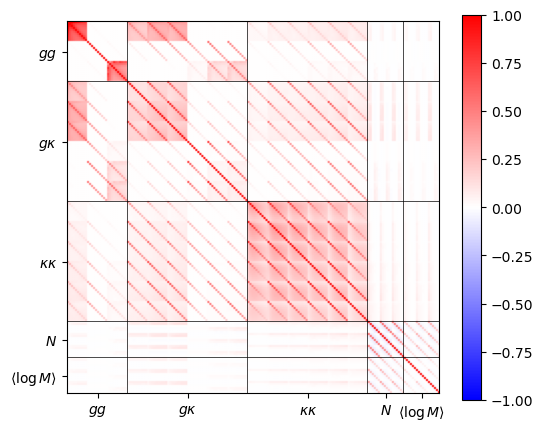

In [5]:
order = np.concatenate([icl, icc, imm])
c = cov[np.ix_(order, order)]
corr = c / np.sqrt(np.outer(np.diag(c), np.diag(c)))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="bwr", vmin=-1, vmax=1)
sizes = [igg.size, igk.size, ikk.size, icc.size, imm.size]
edges = np.cumsum(sizes)[:-1]
for e in edges:
    ax.axhline(e - 0.5, c="k", lw=0.5)
    ax.axvline(e - 0.5, c="k", lw=0.5)
centres = np.array([0, *edges]) + np.array(sizes) / 2
labels = ["$gg$", r"$g\kappa$", r"$\kappa\kappa$", "$N$", r"$\langle\log M\rangle$"]
ax.set_xticks(centres, labels)
ax.set_yticks(centres, labels)
fig.colorbar(im, ax=ax)
plt.show()

In [7]:
# Save the SACC file with the joint covariance (and one per term)
s_cov = cc.create_sacc_cov(output="3x2pt_clusters_with_cov.fits", save_terms=True)

/opt/anaconda3/envs/ccl-dev/lib/python3.13/site-packages/tjpcov/covariance_io.py:93: UserWarning: Output file ./output_joint/3x2pt_clusters_with_cov.fits already exists. Appending the UTC time to the filename to avoid losing the covariance computation. Writing sacc file to {output_new}
  warnings.warn(
/opt/anaconda3/envs/ccl-dev/lib/python3.13/site-packages/tjpcov/covariance_io.py:93: UserWarning: Output file ./output_joint/3x2pt_clusters_with_cov_gauss.fits already exists. Appending the UTC time to the filename to avoid losing the covariance computation. Writing sacc file to {output_new}
  warnings.warn(
/opt/anaconda3/envs/ccl-dev/lib/python3.13/site-packages/tjpcov/covariance_io.py:93: UserWarning: Output file ./output_joint/3x2pt_clusters_with_cov_SSC.fits already exists. Appending the UTC time to the filename to avoid losing the covariance computation. Writing sacc file to {output_new}
  warnings.warn(
/opt/anaconda3/envs/ccl-dev/lib/python3.13/site-packages/tjpcov/covariance_io.